In [9]:
!pip install -q noisereduce
import torch
import torchaudio
import noisereduce as nr
import soundfile as sf
import numpy as np
import os

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cuda


In [10]:
import glob

dataset_path = "/content/dataset/50_speakers_audio_data"
audio_files = glob.glob(dataset_path + "/**/*.wav", recursive=True)
print(f"Found {len(audio_files)} audio files.")


Found 2511 audio files.


In [11]:
def get_dynamic_snr(signal, frame_len=2048):
    if isinstance(signal, np.ndarray):
        t_sig = torch.from_numpy(signal)
    else:
        t_sig = signal
    
    # Unfold for short windows
    if t_sig.numel() < frame_len:
        return 0.0
    unfolded = t_sig.unfold(0, frame_len, frame_len // 2)
    rms = torch.sqrt(torch.mean(unfolded ** 2, dim=1) + 1e-9)
    sorted_rms, _ = torch.sort(rms)
    k = max(1, int(len(rms) * 0.1))
    speech_power = torch.mean(sorted_rms[-k:] ** 2)
    noise_power = torch.mean(sorted_rms[:k] ** 2)
    return float(10 * torch.log10(speech_power / (noise_power + 1e-9)))


In [12]:
def stationary_noise_reduction(y, sr=16000):
    # noisereduce supports use_torch=True and device for fast GPU spectral gating
    use_gpu = torch.cuda.is_available()
    return nr.reduce_noise(
        y=y, sr=sr, stationary=True, prop_decrease=0.9, 
        use_torch=use_gpu, device=str(device)
    )


In [13]:
def silence_trimming(y, sr=16000, top_db=25, frame_len=512, hop_len=128):
    t_y = torch.from_numpy(y) if isinstance(y, np.ndarray) else y
    if t_y.numel() < frame_len:
        return y
    
    # Frame-level RMS energy
    frames = t_y.unfold(0, frame_len, hop_len)
    frame_rms = torch.sqrt(torch.mean(frames ** 2, dim=1) + 1e-9)
    max_rms = torch.max(frame_rms)
    
    # dB threshold relative to max
    threshold = max_rms * (10 ** (-top_db / 20.0))
    voiced_frames = torch.where(frame_rms >= threshold)[0]
    
    if len(voiced_frames) == 0:
        return y
    
    start_sample = voiced_frames[0].item() * hop_len
    end_sample = min(voiced_frames[-1].item() * hop_len + frame_len, len(t_y))
    
    trimmed = t_y[start_sample:end_sample]
    return trimmed.numpy() if isinstance(y, np.ndarray) else trimmed


In [14]:
def RMS_normalization(y, target_rms=0.05):
    rms = np.sqrt(np.mean(y ** 2))
    if rms > 1e-6:
        y = y * (target_rms / rms)
        y = np.clip(y, -1.0, 1.0)
    return y


In [15]:
def preprocessing_pipeline(file_path):
    # Fast PCM load with soundfile
    y_orig, sr = sf.read(file_path, dtype='float32')
    if y_orig.ndim > 1:
        y_orig = np.mean(y_orig, axis=1)
    if sr != 16000:
        t_y = torchaudio.functional.resample(torch.from_numpy(y_orig), sr, 16000)
        y_orig = t_y.numpy()
        sr = 16000

    orig_dur = len(y_orig) / sr
    orig_snr = get_dynamic_snr(y_orig)

    # 1. Stationary noise reduction (GPU accelerated)
    y_clean = stationary_noise_reduction(y_orig, sr)

    # 2. Silence trimming (VAD trim)
    y_voiced = silence_trimming(y_clean, sr)

    # 3. RMS normalization
    y_normalized = RMS_normalization(y_voiced)

    clean_dur = len(y_normalized) / sr
    clean_snr = get_dynamic_snr(y_normalized)

    stats = {
        'file_path': file_path,
        'orig_duration_s': round(orig_dur, 3),
        'clean_duration_s': round(clean_dur, 3),
        'orig_snr_db': round(orig_snr, 2),
        'clean_snr_db': round(clean_snr, 2),
    }

    return y_orig, y_normalized, sr, stats


In [16]:
import os
import soundfile as sf
import pandas as pd
from tqdm import tqdm

source_root = "/content/dataset"
target_root = "/content/cleaned_dataset"

log_records = []
sample_plots_data = []  # save samples for waveform plotting

print(f"Preprocessing {len(audio_files)} files with full pipeline...")

for i, fpath in enumerate(tqdm(audio_files)):
    try:
        y_orig, y_clean, sr, stats = preprocessing_pipeline(fpath)
        
        rel_path = os.path.relpath(fpath, source_root)
        target_path = os.path.join(target_root, rel_path)
        os.makedirs(os.path.dirname(target_path), exist_ok=True)
        sf.write(target_path, y_clean, sr)
        
        stats['clean_file_path'] = target_path
        log_records.append(stats)
        
        if len(sample_plots_data) < 3:
            sample_plots_data.append((os.path.basename(fpath), y_orig, y_clean, sr))
    except Exception as e:
        print(f"Error processing {fpath}: {e}")

# Save processing log CSV deliverable
df_log = pd.DataFrame(log_records)
df_log.to_csv("processing_log.csv", index=False)
print(f"\nSaved processing_log.csv ({len(df_log)} rows)")
display(df_log.head())


Preprocessing 2511 files with full pipeline...


100%|██████████| 2511/2511 [03:41<00:00, 11.32it/s]


Saved processing_log.csv (2511 rows)


,file_path,orig_duration_s,clean_duration_s,orig_snr_db,clean_snr_db,clean_file_path
0,/content/dataset/50_speakers_audio_data/Speake...,60.0,60.0,5.13,23.30,/content/cleaned_dataset/50_speakers_audio_dat...
1,/content/dataset/50_speakers_audio_data/Speake...,60.0,60.0,4.02,22.06,/content/cleaned_dataset/50_speakers_audio_dat...
2,/content/dataset/50_speakers_audio_data/Speake...,60.0,60.0,6.33,24.36,/content/cleaned_dataset/50_speakers_audio_dat...
3,/content/dataset/50_speakers_audio_data/Speake...,60.0,60.0,4.47,20.55,/content/cleaned_dataset/50_speakers_audio_dat...
4,/content/dataset/50_speakers_audio_data/Speake...,60.0,60.0,5.02,23.50,/content/cleaned_dataset/50_speakers_audio_dat...


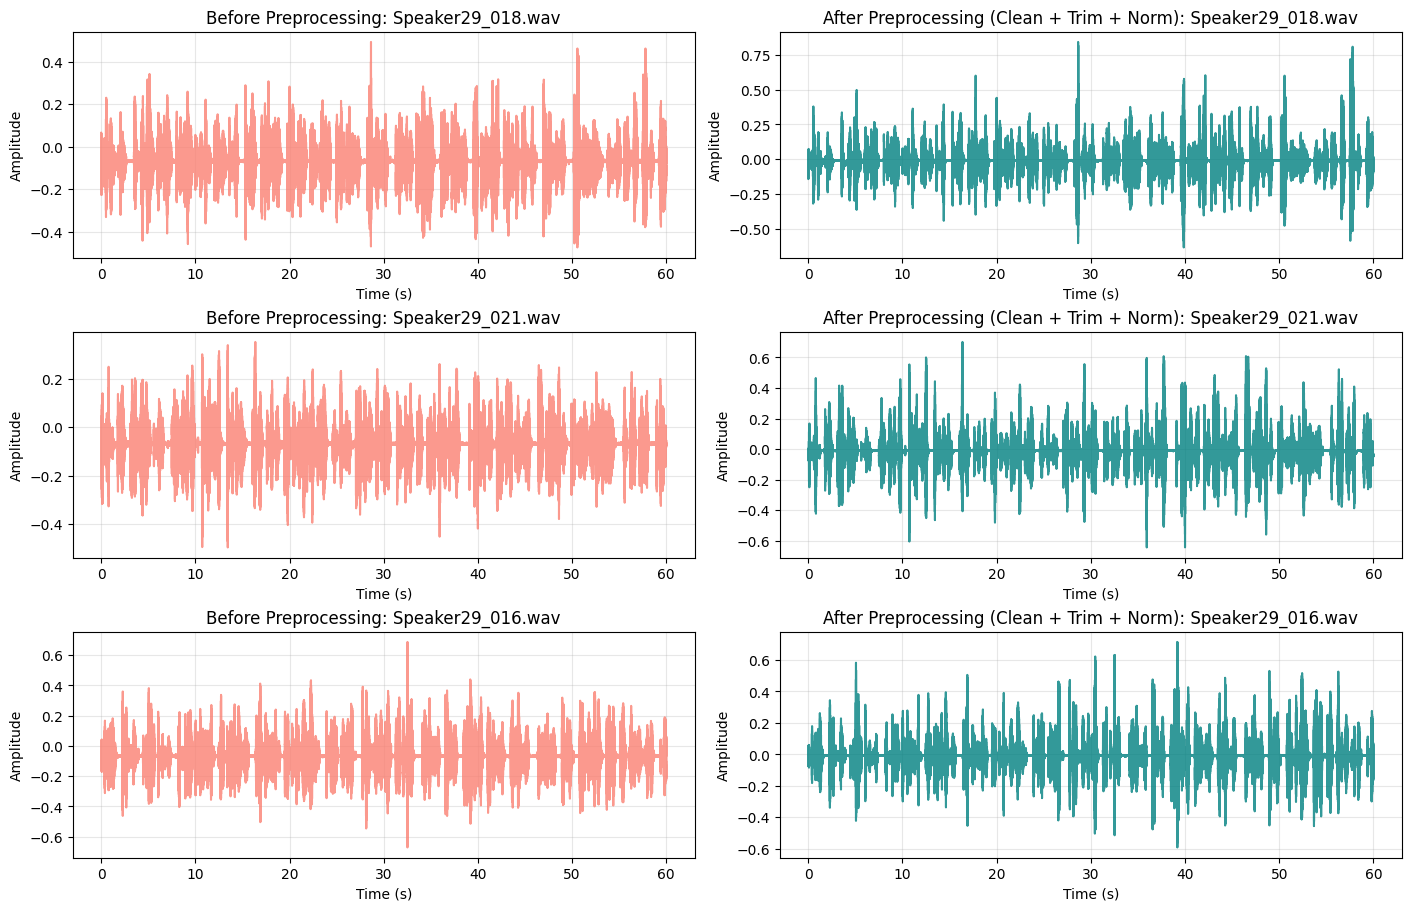

In [ ]:
import matplotlib.pyplot as plt

# Before / After Waveform Plots
fig, axes = plt.subplots(len(sample_plots_data), 2, figsize=(14, 3 * len(sample_plots_data)), constrained_layout=True)

for idx, (fname, y_orig, y_clean, sr) in enumerate(sample_plots_data):
    t_orig = np.linspace(0, len(y_orig) / sr, len(y_orig))
    t_clean = np.linspace(0, len(y_clean) / sr, len(y_clean))
    
    axes[idx, 0].plot(t_orig, y_orig, color='salmon', alpha=0.8)
    axes[idx, 0].set_title(f"Before Preprocessing: {fname}")
    axes[idx, 0].set_xlabel("Time (s)")
    axes[idx, 0].set_ylabel("Amplitude")
    axes[idx, 0].grid(True, alpha=0.3)
    
    axes[idx, 1].plot(t_clean, y_clean, color='teal', alpha=0.8)
    axes[idx, 1].set_title(f"After Preprocessing (Clean + Trim + Norm): {fname}")
    axes[idx, 1].set_xlabel("Time (s)")
    axes[idx, 1].set_ylabel("Amplitude")
    axes[idx, 1].grid(True, alpha=0.3)

plt.savefig("before_after_waveforms.png", dpi=150)
plt.show()
